# KhabarNazar — Urdu Fake News Detection: Data → Model

This notebook builds the Urdu text classifier for KhabarNazar from scratch: it downloads the public Urdu fake-news
datasets, cleans and merges them, checks them for shortcuts, trains baselines, fine-tunes **XLM-RoBERTa**, evaluates it
honestly, and saves a model + `predict()` function for the FastAPI backend.

| Part | What happens | Needs GPU? |
|---|---|---|
| A. Setup | install, imports, config | no |
| B. Get the data | download Hook and Bait and Bend the Truth; load both into one format | no |
| C. Clean and merge | Urduhack normalization, de-duplication, leakage audit, merged CSV, train/val/test split | no |
| D. Baselines | length-only baseline, character TF-IDF + Logistic Regression | no |
| E. Transformer | fine-tune XLM-RoBERTa, evaluate (in-domain + external test), error analysis | **yes** |
| F. Deploy | save model, inference class for FastAPI, optional SHAP explanations | yes (or CPU, slower) |

**Datasets used**

| Dataset | Size | What it is | Role here |
|---|---|---|---|
| Hook and Bait Urdu (Harris et al., *Scientific Reports* 2025) | 78,409 (42,179 true / 36,230 fake) | headlines + short summaries from Urdu news and fact-checking sites; part of the fake side is translated from English fact-checkers (Snopes, PolitiFact) | main training data |
| Bend the Truth (Amjad et al., 2020) | 900 (500 real / 400 fake) | full-length articles; fakes written by journalists | **held out completely** as an external test set |

> Not used: **Ax-to-Grind** (10,083 items; about 95% of it is already inside Hook and Bait, same authors).
> FIRE 2020's test set (in the same repo as Bend the Truth) has no public labels, so it is not used.
> FIRE 2021 is an extension of Bend the Truth and is not in a public repo.

**Where to run:** Google Colab (Runtime → Change runtime type → **T4 GPU**) or the uni PC if it has an NVIDIA GPU.
Parts A–D run on any machine in a few minutes. Part E on a T4 takes roughly 10–20 min per epoch on the full data.

---
# Part A — Setup
## 1. Install packages
**On your own PC:** install PyTorch with GPU support in the terminal *before* running this (see `text_module/README.md`);
this cell does not install PyTorch, because a plain `pip install torch` on Windows gives a CPU-only version.
In Colab PyTorch is already installed.

`urduhack` is installed with `--no-deps` on purpose: its full install pins an old TensorFlow. We only need its
normalization module, and step 7 loads that module without importing TensorFlow. `regex` is the one small package
that module needs.

In [1]:
%pip install -q transformers datasets accelerate scikit-learn sentencepiece openpyxl regex matplotlib seaborn
%pip install -q urduhack --no-deps
# optional, only for step 24 (explanations):
# %pip install -q shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.5/105.5 kB 4.2 MB/s eta 0:00:00


## 2. Imports and GPU check

In [2]:
import os, re, sys, json, random, unicodedata, glob, gc, types, importlib.util, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.1.3


In [3]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU: Parts A-D will run fine; Part E (transformer training) will be very slow on CPU.")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 2b. Google Colab only: get the KhabarNazar repo
Skip this on your own computer (it does nothing there). In Colab it:
1. connects your Google Drive (the trained model is copied there at the end, so it isn't lost);
2. downloads your team's repo from GitHub and switches to a branch called `text-model`;
3. asks you to choose **KhabarNazar_text_module_update.zip** the first time, and puts those files into the repo;
4. moves into `text_module/notebooks`, so the rest of the notebook saves everything in the right places.

If Colab restarts (for example "Restart session" after installing), run this cell again before continuing.

In [4]:
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/azmkh/KhabarNazar.git"
COLAB_REPO = Path("/content/KhabarNazar")

def sh(*cmd, check=True):
    r = subprocess.run(list(cmd), capture_output=True, text=True)
    if r.stdout.strip(): print(r.stdout.strip())
    if r.returncode != 0 and check:
        raise RuntimeError(r.stderr.strip())
    return r

if IN_COLAB:
    from google.colab import drive, files
    try:
        drive.mount("/content/drive")
    except Exception as e:   # e.g. "credential propagation was unsuccessful"
        print("Google Drive NOT connected, continuing without it:", e)
        print("Before step 25: click the folder icon on the left -> 'Mount Drive', so the model can be saved.")
    if not COLAB_REPO.exists():
        sh("git", "clone", REPO_URL, str(COLAB_REPO))
    os.chdir(COLAB_REPO)
    if sh("git", "checkout", "text-model", check=False).returncode != 0:
        sh("git", "checkout", "-b", "text-model")
    if not (COLAB_REPO / "backend/app/ai/text/transformer_model.py").exists():
        print("Choose KhabarNazar_text_module_update.zip in the box below")
        uploaded = files.upload()
        zip_name = next(iter(uploaded))
        import zipfile
        zipfile.ZipFile(zip_name).extractall(COLAB_REPO)
        os.remove(zip_name)
    os.chdir(COLAB_REPO / "text_module" / "notebooks")
    print("now in:", Path.cwd())
    sh("git", "-C", str(COLAB_REPO), "status", "--short")
else:
    print("Not in Colab: nothing to do here.")

Mounted at /content/drive
Choose KhabarNazar_text_module_update.zip in the box below


Saving KhabarNazar_text_module_update (2).zip to KhabarNazar_text_module_update (2).zip
now in: /content/KhabarNazar/text_module/notebooks
M .gitignore
 M backend/README.md
 M backend/app/ai/text/explain.py
 M backend/app/ai/text/predict.py
 M backend/app/ai/text/preprocess.py
 M backend/requirements.txt
?? backend/app/ai/text/transformer_model.py
?? backend/tests/test_text_transformer.py
?? text_module/


## 3. Configuration
Everything you might want to change is in this cell.

In [5]:
# Where things go. Inside the KhabarNazar repo (text_module/notebooks/) the model is saved straight into
# models/text/xlmr/, where the backend looks for it. Anywhere else (e.g. Colab) everything stays next to the notebook.
NB_DIR     = Path.cwd()
REPO_ROOT  = NB_DIR.parent.parent
IN_REPO    = (REPO_ROOT / "backend" / "app" / "ai" / "text").is_dir()
MODULE_DIR = NB_DIR.parent if IN_REPO else NB_DIR

DATA_DIR   = MODULE_DIR / "data"      # raw datasets (not in git)
WORK_DIR   = MODULE_DIR / "work"      # merged CSV, splits, training checkpoints (not in git)
SPLIT_DIR  = WORK_DIR / "splits"
OUTPUT_DIR = MODULE_DIR / "outputs"   # results tables and charts (these ARE pushed to git)
MODEL_DIR  = (REPO_ROOT / "models" / "text" / "xlmr") if IN_REPO else (WORK_DIR / "model_xlmr")
for d in (DATA_DIR, WORK_DIR, SPLIT_DIR, OUTPUT_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("inside KhabarNazar repo:", IN_REPO)
print("model will be saved to:", MODEL_DIR.resolve())

SEED        = 42
MODEL_NAME  = "xlm-roberta-base"

# Leakage control (see step 10). True = drop rows whose text states the verdict ("fake claim", "misleading"...).
REMOVE_VERDICT_ROWS = True

# Shortcut control (see step 7). True = remove punctuation before the model sees the text. In Hook and Bait the real
# BBC/Geo headlines almost never end with a full stop (۔) while most fakes do, so punctuation alone predicts the label
# surprisingly well. Removing it forces the model to learn from the words. The backend reads this from the saved model.
REMOVE_PUNCTUATION = True

# Quick-run switch: set e.g. 15000 to train on a subsample first (checks the pipeline in a few minutes).
# None = use all training data.
TRAIN_SUBSAMPLE = None

# One label convention for the whole project: FAKE = 1, REAL = 0
ID2LABEL = {0: "REAL", 1: "FAKE"}
LABEL2ID = {"REAL": 0, "FAKE": 1}

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass
set_seed()
results = {}     # every evaluation is collected here and saved at the end

inside KhabarNazar repo: True
model will be saved to: /content/KhabarNazar/models/text/xlmr


---
# Part B — Get the data
## 4. Download the datasets
`git clone` works in Colab and on Linux/Mac. On a Windows PC without git, download each repo as a ZIP from GitHub
(green **Code** button → **Download ZIP**) and unzip it into the `data/` folder with the folder names shown below.

| Folder in `data/` | GitHub repo |
|---|---|
| `Hook-and-Bait-Urdu` | github.com/Sheetal83/Hook-and-Bait-Urdu |
| `Datasets-for-Urdu-news` | github.com/MaazAmjad/Datasets-for-Urdu-news (Bend the Truth) |

In [6]:
REPOS = {
    "Hook-and-Bait-Urdu":     "https://github.com/Sheetal83/Hook-and-Bait-Urdu.git",
    "Datasets-for-Urdu-news": "https://github.com/MaazAmjad/Datasets-for-Urdu-news.git",
}
for name, url in REPOS.items():
    target = DATA_DIR / name
    if target.exists():
        print(f"{name}: already present")
        continue
    r = subprocess.run(["git", "clone", "--depth", "1", url, str(target)], capture_output=True, text=True)
    print(f"{name}: {'cloned' if r.returncode == 0 else 'FAILED - download the ZIP manually: ' + r.stderr[:200]}")

# Bend the Truth ships as a zip inside its repo
import zipfile
bt_zip = DATA_DIR / "Datasets-for-Urdu-news" / "Urdu Fake News Dataset.zip"
bt_dir = DATA_DIR / "bend_the_truth"
if bt_zip.exists() and not bt_dir.exists():
    zipfile.ZipFile(bt_zip).extractall(bt_dir)
for p in sorted(DATA_DIR.iterdir()):
    print(" ", p)

Hook-and-Bait-Urdu: cloned
Datasets-for-Urdu-news: cloned
  /content/KhabarNazar/text_module/data/Datasets-for-Urdu-news
  /content/KhabarNazar/text_module/data/Hook-and-Bait-Urdu
  /content/KhabarNazar/text_module/data/bend_the_truth


## 5. Load each dataset into one common format
Every loader returns the same columns: `text`, `label` (1 = FAKE, 0 = REAL), `source`, `domain`.

What the raw files look like (checked before writing this notebook):

- **Hook and Bait**: 6 Excel files, 3 fake + 3 true. Text column `News Items`; label column `Label` (in one file it is
  `"Label "` with a trailing space); labels are `Fake`/`FAKE`/`True`.
- **Bend the Truth**: one `.txt` per article in `1.Corpus/{Train,Test}/{Fake,Real}/`; the file-name prefix is the domain
  (`bus`, `hlth`, `sbz` = showbiz, `sp` = sports, `tch` = technology).

In [7]:
LABEL_WORDS = {"FAKE": 1, "FALSE": 1, "TRUE": 0, "REAL": 0}

def to_label(v):
    key = str(v).strip().upper()
    return LABEL_WORDS.get(key, np.nan)          # anything unexpected becomes NaN and is dropped

def load_hook_and_bait(root=DATA_DIR / "Hook-and-Bait-Urdu"):
    frames = []
    for f in sorted(root.glob("*.xlsx")):
        d = pd.read_excel(f)
        d.columns = [str(c).strip() for c in d.columns]          # fixes "Label " in one file
        frames.append(pd.DataFrame({"text": d["News Items"], "label": d["Label"].map(to_label),
                                    "source": "hook_and_bait", "domain": "unknown", "file": f.name}))
    return pd.concat(frames, ignore_index=True)

BT_DOMAINS = {"bus": "business", "hlth": "health", "sbz": "showbiz", "sp": "sports", "tch": "technology"}

def load_bend_the_truth(root=DATA_DIR / "bend_the_truth"):
    rows = []
    for p in root.rglob("*.txt"):
        cls = p.parent.name.upper()                               # Fake / Real
        prefix = re.match(r"[a-z]+", p.stem).group(0)
        rows.append({"text": p.read_text(encoding="utf-8", errors="ignore"),
                     "label": LABEL_WORDS[cls], "source": "bend_the_truth",
                     "domain": BT_DOMAINS.get(prefix, prefix), "file": p.name})
    return pd.DataFrame(rows)

def tidy(d):
    d = d.dropna(subset=["text", "label"]).copy()
    d["text"] = d["text"].astype(str)
    d["label"] = d["label"].astype(int)
    return d[d["text"].str.strip().str.len() > 0].reset_index(drop=True)

hb, bt = tidy(load_hook_and_bait()), tidy(load_bend_the_truth())
for name, d in [("Hook and Bait", hb), ("Bend the Truth", bt)]:
    print(f"{name:15s} rows={len(d):6d}   fake={int(d.label.sum()):6d}   real={int((d.label == 0).sum()):6d}")

Hook and Bait   rows= 78409   fake= 36230   real= 42179
Bend the Truth  rows=   900   fake=   400   real=   500


In [8]:
hb.sample(5, random_state=1)[["text", "label", "file"]]

,text,label,file
46404,ہوپ کک: سکم کی رانی جنھیں سی آئی ایجنٹ اور آزاد ریاست کے انڈیا میں انضمام کا سبب قرار دیا گیا,0,Final True News-11012.xlsx
31402,ویڈیو میں پاکستان میں مذہبی تبدیلی سے منسلک ہونے کا دعوی کیا گیا ہے,1,Fake_News_After_31190.xlsx
20548,ماس میں پوپ فرانسس: یسوع استعاراتی ہے، لفظی نہیں۔,1,Fake News After 12166.xlsx
3519,یہ آر ایس ایس کے سربراہ موہن بھاگوت کے ساتھ دروپدی مرمو کی ترمیم شدہ تصویر ہے۔,1,Fake News 12166.xlsx
27489,وشال سمندری مخلوق سانتا مونیکا کوسٹ لائن کے ساتھ ساحل کو دھو رہی ہے۔,1,Fake News After 12166.xlsx


## 6. Look at the data: class balance and length per class
**Why length matters.** If fake items are systematically longer (or shorter) than real ones, a model can score well just
by measuring length, without understanding anything. A 2026 study found exactly this in another Urdu dataset (Ax-to-Grind): fake items
average about 117 words versus about 35 for real ones, and an XLM-R model trained on it collapsed when tested on another
Urdu dataset. So we measure it here, and step 12 tests how far length alone gets.

count   mean    50%     max
source         label                               
bend_the_truth FAKE     400.0  300.8  251.0  1203.0
               REAL     500.0  373.0  274.0  2199.0
hook_and_bait  FAKE   36230.0   26.4   17.0  1114.0
               REAL   42179.0   21.1   15.0   360.0

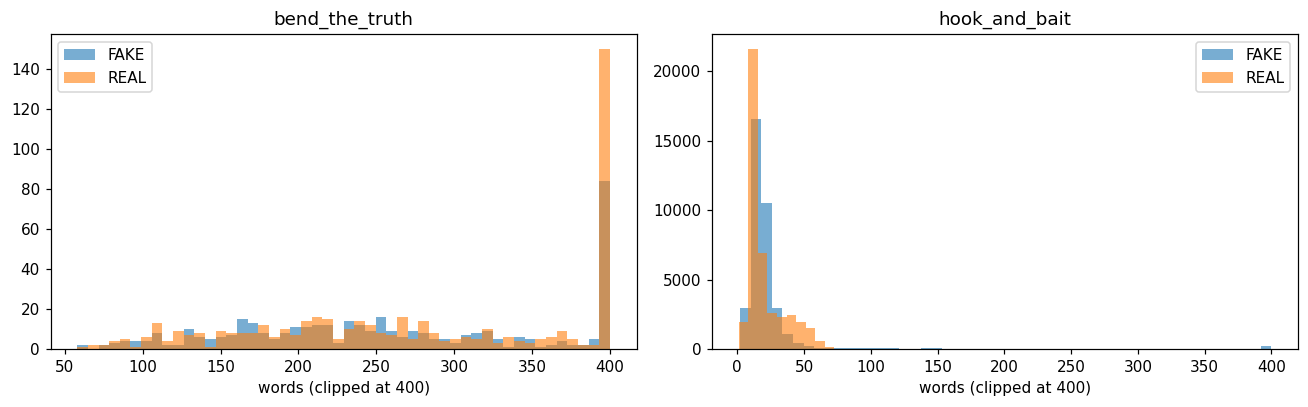

In [9]:
raw = pd.concat([hb, bt], ignore_index=True)
raw["n_words"] = raw["text"].str.split().str.len()

length_table = (raw.groupby(["source", raw["label"].map(ID2LABEL)])["n_words"]
                   .describe()[["count", "mean", "50%", "max"]].round(1))
display(length_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for a, (src, g) in zip(axes, raw.groupby("source")):
    for lab, gg in g.groupby(g["label"].map(ID2LABEL)):
        a.hist(gg["n_words"].clip(upper=400), bins=50, alpha=0.6, label=lab)
    a.set_title(src); a.set_xlabel("words (clipped at 400)"); a.legend()
plt.tight_layout(); plt.show()

**How to read this:** Hook and Bait items are short headlines (median roughly 15–17 words) for both classes, which is good.
Bend the Truth is full articles (hundreds of words),
a completely different style, which is why it makes a good external test.

---
# Part C — Clean and merge
## 7. Urdu normalization with Urduhack
Urdu text copied from different websites mixes **Arabic and Urdu Unicode characters that look identical** (Arabic `ي` vs
Urdu `ی`, Arabic `ك` vs Urdu `ک`, presentation forms like `ﺁ`). To the tokenizer these are different characters, so the
same word gets split differently depending on the website. Urduhack's `normalize()` maps everything to the standard Urdu
range (U+0600–U+06FF) and fixes joined words.

The loading trick below imports only `urduhack.normalization`. A plain `import urduhack` would also import its NER and
pipeline models, which require TensorFlow. If Urduhack is missing, a small built-in fallback does the most important
character fixes.

**Punctuation is removed too** (`REMOVE_PUNCTUATION = True`, step 3). The trial run showed why: in Hook and Bait the
real BBC and Geo headlines almost never end with a full stop (۔), while about 60% of the fakes do, and fakes use more
question marks. A model that sees only the punctuation, with no words at all, already scores about 0.79 macro-F1. That is
a formatting shortcut, not news understanding, and it would mislead the app (a user's pasted text may or may not end
with ۔). Step 13 prints both versions of the TF-IDF baseline so you can report the difference.

What we deliberately do **not** do for a transformer: remove stop words, stem, or lower-case. The model needs those words
as context, and the multilingual tokenizer was trained on normal text.

In [10]:
def load_urduhack_normalize():
    spec = importlib.util.find_spec("urduhack")
    if spec is None:
        raise ImportError("urduhack not installed")
    if "urduhack" not in sys.modules:                       # register an empty package so __init__ (TensorFlow) is skipped
        pkg = types.ModuleType("urduhack")
        pkg.__path__ = list(spec.submodule_search_locations)
        sys.modules["urduhack"] = pkg
    from urduhack.normalization import normalize
    return normalize

try:
    uh_normalize = load_urduhack_normalize()
    print("Urduhack normalization loaded")
except Exception as e:
    uh_normalize = None
    print("Urduhack unavailable, using fallback:", e)

ARABIC_TO_URDU = {"ي": "ی", "ى": "ی", "ك": "ک",
                  "ه": "ہ", "ة": "ۃ"}
DIACRITICS = re.compile("[ً-ْٰ]")
DIGITS     = str.maketrans("٠١٢٣٤٥٦٧٨٩۰۱۲۳۴۵۶۷۸۹", "01234567890123456789")
URL_RE     = re.compile(r"https?://\S+|www\.\S+")
HTML_RE    = re.compile(r"<[^>]+>")
SPACE_RE   = re.compile(r"\s+")

def fallback_normalize(text):
    text = unicodedata.normalize("NFKC", text)              # also folds Arabic presentation forms
    for a, u in ARABIC_TO_URDU.items():
        text = text.replace(a, u)
    return text

PUNCT_RE   = re.compile(r"[۔،؟؛٪!?.,:;'\"‘’“”«»()\[\]{}\-–—…/\\|*_~`@#]+")

def clean_text(text, remove_punctuation=None):
    if remove_punctuation is None:
        remove_punctuation = REMOVE_PUNCTUATION
    text = HTML_RE.sub(" ", str(text))
    text = URL_RE.sub(" ", text)
    text = uh_normalize(text) if uh_normalize else fallback_normalize(text)
    text = DIACRITICS.sub("", text)                         # zabar/zer/pesh are used inconsistently across sites
    text = text.translate(DIGITS)
    text = text.replace("‌", " ").replace("​", "").replace("﻿", "")
    if remove_punctuation:
        text = PUNCT_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip()

demo = "يہ خبر كے مطابق ﺁج ١٢ بجے https://example.com"
print("before:", demo, [hex(ord(c)) for c in demo[:2]])
print("after :", clean_text(demo), [hex(ord(c)) for c in clean_text(demo)[:2]])

raw["text_clean"] = raw["text"].map(clean_text)
raw = raw[raw["text_clean"].str.len() >= 15].reset_index(drop=True)

Urduhack normalization loaded
before: يہ خبر كے مطابق ﺁج ١٢ بجے https://example.com ['0x64a', '0x6c1']
after : یہ خبر کے مطابق آج 12 بجے ['0x6cc', '0x6c1']


## 8. Duplicates
Hook and Bait was assembled from several scrapes, so some items appear more than once. If a copy lands in both train
and test, the test score is inflated, because the model has already seen that exact item. The next cell counts duplicates
using a key made of letters and digits only (so punctuation or spacing differences don't hide a duplicate).

In [11]:
raw["key"] = raw["text_clean"].str.replace(r"[\W_]+", "", regex=True)
dup = raw.duplicated("key", keep=False)
print(f"items that have at least one duplicate: {dup.sum()} ({dup.mean():.1%})")
display(raw[dup].sort_values("key")[["text_clean", "label", "file"]].head(10))

items that have at least one duplicate: 3128 (3.9%)


,text_clean,label,file
46483,100 گز کے مکان کا مالک پراپرٹی ٹیکس دیکھ کر بے ہوش,0,Final True News-11012.xlsx
66729,100 گز کے مکان کا مالک پراپرٹی ٹیکس دیکھ کر بے ہوش,0,True_News_after_11012.xlsx
73124,10 برس میں پہلی بار زیر التوا مقدمات میں کمی سپریم کورٹ نے تفصیل جاری کر دی,0,True_News_after_11012.xlsx
44787,10 برس میں پہلی بار زیر التوا مقدمات میں کمی سپریم کورٹ نے تفصیل جاری کر دی,0,Final True News-11012.xlsx
61418,10سالہ بچی نے بنا اسکول کی چھٹی کیے 50 ممالک کا سفر کیسےکیا,0,True_News_after_11012.xlsx
38376,10سالہ بچی نے بنا اسکول کی چھٹی کیے 50 ممالک کا سفر کیسےکیا,0,Final True News-11012.xlsx
61387,110 سال کی عمر میں تعلیم حاصل کرنیوالی سعودی خاتون,0,True_News_after_11012.xlsx
38345,110 سال کی عمر میں تعلیم حاصل کرنیوالی سعودی خاتون,0,Final True News-11012.xlsx
44927,184 3 کیخلاف کسی بھی ریمیڈی کو ویلکم کرینگے چیف جسٹس,0,Final True News-11012.xlsx
73068,184 3 کیخلاف کسی بھی ریمیڈی کو ویلکم کرینگے چیف جسٹس,0,True_News_after_11012.xlsx


## 9. Merge, de-duplicate, drop label conflicts
Rules:
1. When the same text appears more than once, keep **one** copy (a Bend the Truth copy wins, so the external
   test set stays complete).
2. If the same text appears with **opposite labels**, drop it entirely; we can't know which label is right.

In [12]:
PRIORITY = {"bend_the_truth": 0, "hook_and_bait": 1}
before = len(raw)

conflicts = raw.groupby("key")["label"].nunique()
conflict_keys = set(conflicts[conflicts > 1].index)
merged = raw[~raw["key"].isin(conflict_keys)].copy()

merged["prio"] = merged["source"].map(PRIORITY)
merged = (merged.sort_values("prio").drop_duplicates("key", keep="first")
                .drop(columns="prio").reset_index(drop=True))

print(f"rows before: {before}")
print(f"texts with conflicting labels dropped: {len(conflict_keys)}")
print(f"rows after de-duplication: {len(merged)}")
display(pd.crosstab(merged["source"], merged["label"].map(ID2LABEL), margins=True))

rows before: 79281
texts with conflicting labels dropped: 22
rows after de-duplication: 77691


label,FAKE,REAL,All
source,,,
bend_the_truth,398,494,892
hook_and_bait,35755,41044,76799
All,36153,41538,77691


## 10. Leakage audit: does the text give away the answer?
Much of Hook and Bait's fake side comes from **fact-checking websites** (Vishvas News, ARY fact-check). A fact-check
headline often contains the verdict itself, e.g. *"…تصویر فرضی دعوی کے ساتھ وائرل"* ("…image viral with a false claim")
or *"وائرل دعویٰ گمراہ کن ہے"* ("the viral claim is misleading"). A model trained on these learns "the word *fake* means
FAKE", which scores well on the test set but is useless in the app, where users paste the *claim*, not the fact-check.

The cell below counts verdict words per class. With `REMOVE_VERDICT_ROWS = True`, rows containing an explicit verdict
word are removed from the training sources, **in both classes** (so the filter itself doesn't create a new bias). Write the before/after numbers into your report — it's a real finding about the
dataset.

In [13]:
# words are written as they look AFTER clean_text (diacritics removed, so "دعویٰ" becomes "دعوی")
VERDICT_WORDS = ["فرضی", "جعلی", "گمراہ", "جھوٹ", "فیک", "فیکٹ چیک", "حقیقت جانیں", "دعوی", "وائرل",
                 "fact check", "fact-check", "factcheck", "fake"]   # English giveaways found in the trial run
verdict_re = re.compile("|".join(map(re.escape, VERDICT_WORDS)), flags=re.IGNORECASE)
merged["has_verdict_word"] = merged["text_clean"].str.contains(verdict_re)

audit = (merged.groupby(["source", merged["label"].map(ID2LABEL)])["has_verdict_word"]
               .mean().mul(100).round(1).unstack())
print("% of items containing a verdict word:")
display(audit)

per_word = pd.DataFrame({w: merged.groupby(merged["label"].map(ID2LABEL))["text_clean"]
                                   .apply(lambda s: s.str.contains(re.escape(w), case=False).mean() * 100)
                         for w in VERDICT_WORDS}).T.round(2)
display(per_word.sort_values("FAKE", ascending=False))

if REMOVE_VERDICT_ROWS:
    # Only the training sources are filtered. Bend the Truth is journalist-written articles (no fact-check verdicts),
    # where words like "claim" occur naturally, so the external test set stays untouched.
    n0 = len(merged)
    drop = merged["has_verdict_word"] & (merged["source"] != "bend_the_truth")
    merged = merged[~drop].reset_index(drop=True)
    print(f"Removed {n0 - len(merged)} rows containing verdict words -> {len(merged)} rows remain")
display(pd.crosstab(merged["source"], merged["label"].map(ID2LABEL), margins=True))

% of items containing a verdict word:


label,FAKE,REAL
source,,
bend_the_truth,11.6,15.4
hook_and_bait,21.3,3.5


label,FAKE,REAL
دعوی,6.69,0.91
وائرل,6.56,1.67
جھوٹ,6.09,0.19
جعلی,3.72,0.28
گمراہ,3.34,0.06
فرضی,1.28,0.07
فیک,1.10,0.51
فیکٹ چیک,0.47,0.01
حقیقت جانیں,0.02,0.00
factcheck,0.01,0.00


Removed 9033 rows containing verdict words -> 68658 rows remain


label,FAKE,REAL,All
source,,,
bend_the_truth,398,494,892
hook_and_bait,28142,39624,67766
All,28540,40118,68658


**A second, subtler bias to mention in the report:** part of Hook and Bait's fake news was translated from English
fact-checkers (US politics, e.g. counties in Arizona, Florida), while its true news comes from Pakistani/Indian Urdu
outlets. So *topic* and *translation style* also correlate with the label. We can't fully remove this, which is exactly
why the external Bend the Truth test (step 17) matters. Step 17 also scores each Hook and Bait file
separately, which shows whether the translated-fakes files behave differently.

## 11. Save the merged dataset and make the splits
- **Bend the Truth is held out completely** (`external_test.csv`). It is never used for training or model selection.
- Hook and Bait is split **80 / 10 / 10**, stratified by label, so each part has the same fake/real ratio.
- Everything is saved to CSV, so the baselines, every transformer and your report use exactly the same test set.
  `khabarnazar_urdu_merged.csv` is also the file to feed into the Roman Urdu transliteration step later.

In [14]:
from sklearn.model_selection import train_test_split

cols = ["text_clean", "text", "label", "source", "domain", "file"]
merged[cols].to_csv(WORK_DIR / "khabarnazar_urdu_merged.csv", index=False, encoding="utf-8-sig")

external_df = merged[merged.source == "bend_the_truth"][cols].reset_index(drop=True)
pool        = merged[merged.source != "bend_the_truth"][cols].reset_index(drop=True)

strat = pool["label"].astype(str) + "_" + pool["source"]
train_df, tmp = train_test_split(pool, test_size=0.2, stratify=strat, random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.5, stratify=tmp["label"].astype(str) + "_" + tmp["source"],
                                   random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

for name, d in [("train", train_df), ("val", val_df), ("test", test_df), ("external_test", external_df)]:
    d.to_csv(SPLIT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")
    print(f"{name:14s} {len(d):6d} rows   fake share {d['label'].mean():.1%}")

train           54212 rows   fake share 41.5%
val              6777 rows   fake share 41.5%
test             6777 rows   fake share 41.5%
external_test     892 rows   fake share 44.6%


---
# Part D — Baselines (CPU, a few minutes)
These numbers go in the comparison table of your report. The transformer has to beat them clearly to justify itself.

## 12. Length-only baseline (shortcut check)
A logistic regression that sees **only** word count and character count. If this alone scores far above 50%, the data
contains a length shortcut, and you should say so when reporting the transformer's score.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)

def scores(y_true, y_pred):
    return {"accuracy": round(accuracy_score(y_true, y_pred), 4),
            "f1_macro": round(f1_score(y_true, y_pred, average="macro"), 4),
            "f1_fake":  round(f1_score(y_true, y_pred, pos_label=1), 4),
            "precision_fake": round(precision_score(y_true, y_pred, pos_label=1, zero_division=0), 4),
            "recall_fake":    round(recall_score(y_true, y_pred, pos_label=1, zero_division=0), 4)}

def length_features(s):
    return np.c_[np.log1p(s.str.split().str.len()), np.log1p(s.str.len())]

len_clf = LogisticRegression(max_iter=1000).fit(length_features(train_df.text_clean), train_df.label)
results["Length only (test)"]     = scores(test_df.label, len_clf.predict(length_features(test_df.text_clean)))
results["Length only (external)"] = scores(external_df.label, len_clf.predict(length_features(external_df.text_clean)))
pd.DataFrame(results).T

,accuracy,f1_macro,f1_fake,precision_fake,recall_fake
Length only (test),0.6009,0.5167,0.315,0.548,0.221
Length only (external),0.5527,0.3560,0.000,0.000,0.000


## 13. Character n-gram TF-IDF + Logistic Regression
Character n-grams (2–5 characters inside word boundaries) suit Urdu well and were among the strongest classical features
in the UrduFake shared tasks and Farooq et al.

In [16]:
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=300_000)
X_train = vec.fit_transform(train_df.text_clean)
tfidf_clf = LogisticRegression(max_iter=3000, C=4.0, class_weight="balanced").fit(X_train, train_df.label)

pred_test = tfidf_clf.predict(vec.transform(test_df.text_clean))
pred_ext  = tfidf_clf.predict(vec.transform(external_df.text_clean))
results["TF-IDF char + LogReg (test)"]     = scores(test_df.label, pred_test)
results["TF-IDF char + LogReg (external)"] = scores(external_df.label, pred_ext)

# Shortcut check: how far does punctuation ALONE get? The model below sees only the punctuation marks of the
# original text and its last character, no words at all. Far above 0.5 = punctuation gives the label away.
NOT_PUNCT = re.compile(r"[^۔،؟؛!?.,:;'\"‘’“”()\-]")
def punct_only(d):
    kept = d["text"].map(lambda t: clean_text(t, remove_punctuation=False))
    return kept.map(lambda t: NOT_PUNCT.sub("", t) + " END" + t[-1:])
p_vec = TfidfVectorizer(analyzer="char", ngram_range=(1, 2), lowercase=False)
p_clf = LogisticRegression(max_iter=2000).fit(p_vec.fit_transform(punct_only(train_df)), train_df.label)
results["Punctuation only (test)"] = scores(test_df.label, p_clf.predict(p_vec.transform(punct_only(test_df))))
print("Punctuation-only model, test macro-F1:", results["Punctuation only (test)"]["f1_macro"],
      "| REMOVE_PUNCTUATION =", REMOVE_PUNCTUATION)

print(classification_report(test_df.label, pred_test, target_names=["REAL", "FAKE"], digits=4))
display(pd.DataFrame(results).T)

# accuracy per Hook and Bait file (each file is one class)
display(test_df.assign(correct=(pred_test == test_df.label)).groupby(["file", test_df.label.map(ID2LABEL)])
        ["correct"].agg(n="size", accuracy="mean").round(4))

Punctuation-only model, test macro-F1: 0.7896 | REMOVE_PUNCTUATION = True
              precision    recall  f1-score   support

        REAL     0.9170    0.9059    0.9114      3963
        FAKE     0.8697    0.8845    0.8770      2814

    accuracy                         0.8970      6777
   macro avg     0.8933    0.8952    0.8942      6777
weighted avg     0.8973    0.8970    0.8971      6777



,accuracy,f1_macro,f1_fake,precision_fake,recall_fake
Length only (test),0.6009,0.5167,0.3150,0.5480,0.2210
Length only (external),0.5527,0.3560,0.0000,0.0000,0.0000
TF-IDF char + LogReg (test),0.8970,0.8942,0.8770,0.8697,0.8845
TF-IDF char + LogReg (external),0.5448,0.4974,0.3430,0.4818,0.2663
Punctuation only (test),0.7950,0.7896,0.7558,0.7480,0.7637


,,n,accuracy
file,label,,
Fake News 12166.xlsx,FAKE,680,0.9324
Fake News After 12166.xlsx,FAKE,1752,0.9241
Fake_News_After_31190.xlsx,FAKE,382,0.6178
Final True News-11012.xlsx,REAL,1049,0.9180
True_News_After_28478.xlsx,REAL,1352,0.8462
True_News_after_11012.xlsx,REAL,1562,0.9494


In [17]:
# Which character patterns push towards FAKE / REAL? Useful sanity check and a nice figure for the report.
feat = np.array(vec.get_feature_names_out())
coef = tfidf_clf.coef_[0]
top = pd.DataFrame({"towards FAKE": feat[np.argsort(coef)[-25:][::-1]],
                    "towards REAL": feat[np.argsort(coef)[:25]]})
top

,towards FAKE,towards REAL
0,نے,ہ
1,نے,ت
2,ہ,د
3,ہے,کس
4,ہے,ج
5,ان,مریکا
6,ہے,کیوں
7,ہے,ان
8,ہیں,ریکا
9,ہیں,ب


---
# Part E — Fine-tune XLM-RoBERTa (GPU)
## 14. Why XLM-RoBERTa
- Pre-trained on 100 languages including a large amount of Urdu web text; it is the model your report already commits to.
- It has outperformed mBERT on Urdu and other South Asian fake-news benchmarks in the papers you reviewed.
- The base model (≈280M parameters) fine-tunes comfortably on a free T4. Larger LLMs (LLaMA 2 in the Hook and Bait
  paper, Qalb) need far more GPU memory than you have and are slow to serve from a FastAPI backend.

Step 21 optionally trains mBERT and MuRIL with the same code for a comparison table.

## 15. Token-length analysis → `MAX_LEN`
Shorter `MAX_LEN` = faster training and less memory. We pick the smallest value that covers about 95% of training items.

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (581 > 512). Running this sequence through the model will result in indexing errors


50th percentile: 22 tokens
90th percentile: 51 tokens
95th percentile: 63 tokens
99th percentile: 91 tokens
MAX_LEN = 64 | long items are truncated; the start of a news item carries the main claim


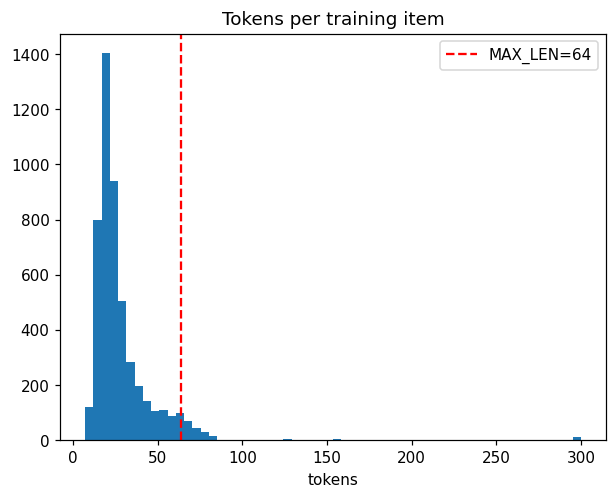

In [18]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

sample = train_df.text_clean.sample(min(5000, len(train_df)), random_state=SEED)
tok_lens = np.array([len(x) for x in tokenizer(list(sample), truncation=False)["input_ids"]])
for p in (50, 90, 95, 99):
    print(f"{p}th percentile: {int(np.percentile(tok_lens, p))} tokens")

p95 = np.percentile(tok_lens, 95)
MAX_LEN = 64 if p95 <= 64 else 128 if p95 <= 128 else 256
print("MAX_LEN =", MAX_LEN, "| long items are truncated; the start of a news item carries the main claim")

plt.hist(np.clip(tok_lens, 0, 300), bins=60); plt.axvline(MAX_LEN, color="r", ls="--", label=f"MAX_LEN={MAX_LEN}")
plt.xlabel("tokens"); plt.legend(); plt.title("Tokens per training item"); plt.show()

## 16. Training setup
| Setting | Value | Why |
|---|---|---|
| learning rate | 2e-5 | standard for XLM-R; higher values often make it diverge |
| batch size | 32 (16 + grad-accum 2 if out of memory) | fits a T4 at MAX_LEN 128 with fp16 |
| epochs | up to 4, early stopping (patience 1) | large data converges fast; stops when validation stops improving |
| warmup | 6% of steps | stabilises the start of training |
| weight decay | 0.01 | mild regularisation |
| model selection | best validation macro-F1 | balanced view of both classes |

In [19]:
from datasets import Dataset
from transformers import (AutoModelForSequenceClassification, TrainingArguments, Trainer,
                          DataCollatorWithPadding, EarlyStoppingCallback)

def to_hf(d, tok, max_len):
    ds = Dataset.from_dict({"text": d["text_clean"].tolist(), "label": d["label"].astype(int).tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=max_len),
                  batched=True, remove_columns=["text"])

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return scores(labels, np.argmax(logits, axis=-1))

def train_transformer(model_name, run_name, train_d, val_d, max_len, epochs=4, lr=2e-5, bs=32, grad_accum=1):
    set_seed()
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID)
    steps_total = int(np.ceil(len(train_d) / (bs * grad_accum))) * epochs
    args = TrainingArguments(
        output_dir=str(WORK_DIR / "runs" / run_name),
        eval_strategy="epoch", save_strategy="epoch",
        learning_rate=lr, num_train_epochs=epochs,
        per_device_train_batch_size=bs, per_device_eval_batch_size=bs * 2,
        gradient_accumulation_steps=grad_accum,
        weight_decay=0.01, warmup_steps=int(0.06 * steps_total),
        load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
        save_total_limit=1, fp16=torch.cuda.is_available(),
        logging_steps=100, report_to="none", seed=SEED,
    )
    trainer = Trainer(model=model, args=args,
                      train_dataset=to_hf(train_d, tok, max_len), eval_dataset=to_hf(val_d, tok, max_len),
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics,
                      callbacks=[EarlyStoppingCallback(early_stopping_patience=1)])
    trainer.train()
    return trainer, tok

In [20]:
if TRAIN_SUBSAMPLE is None or TRAIN_SUBSAMPLE >= len(train_df):
    train_used = train_df
else:
    train_used, _ = train_test_split(train_df, train_size=TRAIN_SUBSAMPLE,
                                     stratify=train_df["label"].astype(str) + "_" + train_df["source"],
                                     random_state=SEED)
print("training on", len(train_used), "rows")

# "CUDA out of memory"? -> bs=16, grad_accum=2 (same effective batch size)
trainer, tok = train_transformer(MODEL_NAME, "xlmr", train_used, val_df, MAX_LEN, bs=32, grad_accum=1)

training on 54212 rows


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Fake,Precision Fake,Recall Fake
1,0.224532,0.215389,0.922200,0.919400,0.904100,0.926900,0.882400
2,0.176450,0.173922,0.938800,0.936500,0.924500,0.947800,0.902300
3,0.113497,0.188510,0.943900,0.942000,0.931400,0.947400,0.915800
4,0.081760,0.229614,0.946100,0.944300,0.934000,0.951400,0.917200


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

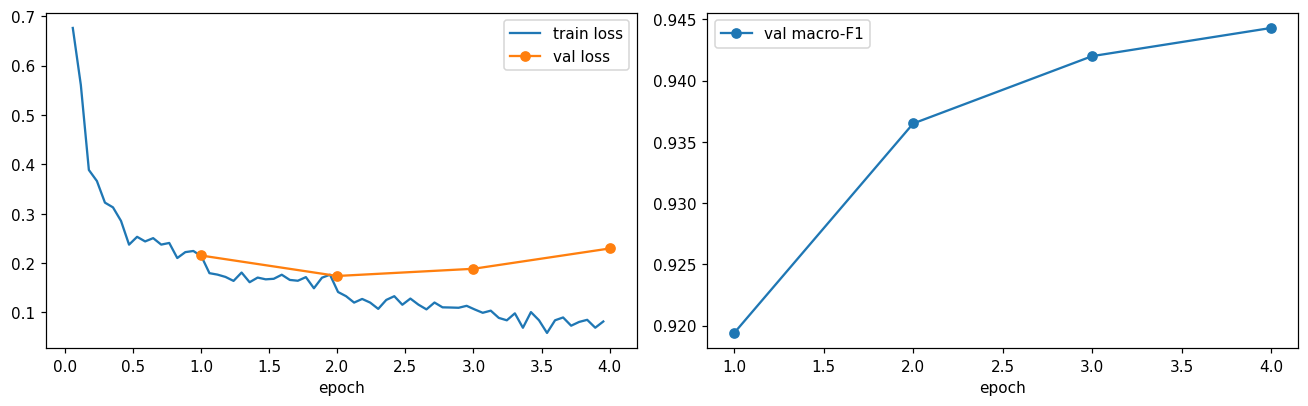

In [21]:
log = pd.DataFrame(trainer.state.log_history)
tr = log.dropna(subset=["loss"]) if "loss" in log else pd.DataFrame()
ev = log.dropna(subset=["eval_loss"])
fig, a = plt.subplots(1, 2, figsize=(12, 3.8))
if len(tr): a[0].plot(tr["epoch"], tr["loss"], label="train loss")
a[0].plot(ev["epoch"], ev["eval_loss"], "o-", label="val loss"); a[0].set_xlabel("epoch"); a[0].legend()
a[1].plot(ev["epoch"], ev["eval_f1_macro"], "o-", label="val macro-F1"); a[1].set_xlabel("epoch"); a[1].legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "training_curves.png"); plt.show()

## 17. Evaluation
Three views, all of which belong in the report:
1. **In-domain test** (Hook and Bait test split): the number papers usually report.
2. **Per Hook and Bait file**: each file holds one class, so this shows accuracy per file. If the translated-fakes
   files score near 100% and the Urdu fact-check file much lower, the model may be recognising translation style.
3. **External test** (Bend the Truth, never seen in training, full-length articles written in a different style):
   the honest estimate of how the model behaves on news it hasn't seen. Expect it to be much lower than (1);
   that gap is a finding, not a failure.

Map:   0%|          | 0/6777 [00:00<?, ? examples/s]

Map:   0%|          | 0/892 [00:00<?, ? examples/s]

IN-DOMAIN TEST
              precision    recall  f1-score   support

        REAL     0.9427    0.9627    0.9526      3963
        FAKE     0.9458    0.9176    0.9315      2814

    accuracy                         0.9439      6777
   macro avg     0.9442    0.9401    0.9420      6777
weighted avg     0.9440    0.9439    0.9438      6777



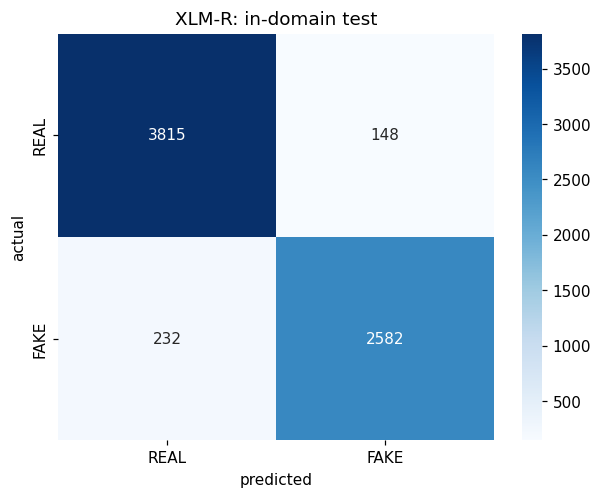

EXTERNAL TEST (Bend the Truth)
              precision    recall  f1-score   support

        REAL     0.6041    0.5931    0.5986       494
        FAKE     0.5061    0.5176    0.5118       398

    accuracy                         0.5594       892
   macro avg     0.5551    0.5554    0.5552       892
weighted avg     0.5604    0.5594    0.5599       892



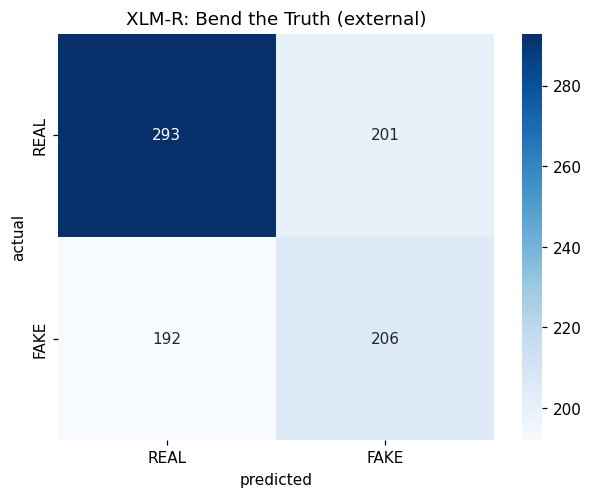

In [22]:
def predict_df(trainer, tok, d, max_len):
    out = trainer.predict(to_hf(d, tok, max_len))
    probs = torch.softmax(torch.tensor(out.predictions, dtype=torch.float32), dim=-1)[:, 1].numpy()
    return (probs >= 0.5).astype(int), probs

def show_cm(y, p, title):
    sns.heatmap(confusion_matrix(y, p), annot=True, fmt="d", cmap="Blues",
                xticklabels=["REAL", "FAKE"], yticklabels=["REAL", "FAKE"])
    plt.xlabel("predicted"); plt.ylabel("actual"); plt.title(title); plt.show()

test_pred, test_prob = predict_df(trainer, tok, test_df, MAX_LEN)
ext_pred,  ext_prob  = predict_df(trainer, tok, external_df, MAX_LEN)
results["XLM-R (test)"]     = scores(test_df.label, test_pred)
results["XLM-R (external)"] = scores(external_df.label, ext_pred)

print("IN-DOMAIN TEST"); print(classification_report(test_df.label, test_pred, target_names=["REAL", "FAKE"], digits=4))
show_cm(test_df.label, test_pred, "XLM-R: in-domain test")
print("EXTERNAL TEST (Bend the Truth)"); print(classification_report(external_df.label, ext_pred, target_names=["REAL", "FAKE"], digits=4))
show_cm(external_df.label, ext_pred, "XLM-R: Bend the Truth (external)")

In [23]:
# each Hook and Bait file holds one class, so accuracy per file = share of that file classified correctly
per_file = (test_df.assign(correct=(test_pred == test_df.label)).groupby(["file", test_df.label.map(ID2LABEL)])
            ["correct"].agg(n="size", accuracy="mean").round(4))
display(per_file)

per_domain = (external_df.assign(pred=ext_pred).groupby("domain")
              .apply(lambda g: pd.Series({"n": len(g), **scores(g.label, g.pred)})))
display(per_domain)     # external test by topic: which news domains transfer worst?

,,n,accuracy
file,label,,
Fake News 12166.xlsx,FAKE,680,0.9574
Fake News After 12166.xlsx,FAKE,1752,0.9498
Fake_News_After_31190.xlsx,FAKE,382,0.6990
Final True News-11012.xlsx,REAL,1049,0.9724
True_News_After_28478.xlsx,REAL,1352,0.9401
True_News_after_11012.xlsx,REAL,1562,0.9757


/tmp/ipykernel_954/826321667.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({"n": len(g), **scores(g.label, g.pred)})))


,n,accuracy,f1_macro,f1_fake,precision_fake,recall_fake
domain,,,,,,
business,149.0,0.5705,0.5135,0.3469,0.3542,0.3400
health,199.0,0.5779,0.5766,0.6000,0.5676,0.6364
showbiz,200.0,0.5150,0.5060,0.5727,0.5118,0.6500
sports,148.0,0.6622,0.5495,0.3243,0.5000,0.2400
technology,196.0,0.5000,0.5000,0.5000,0.5052,0.4949


### 17b. Bend the Truth again, reading whole articles
The model reads at most `MAX_LEN` tokens, so for a 250-word Bend the Truth article it sees only the first few
sentences. To separate "the model can't judge this style of news" from "the model only saw the opening", each article
is also split into 40-word pieces, every piece is scored, and the article's score is the average. Report both numbers.

In [24]:
def chunk_words(t, size=40):
    w = t.split()
    return [" ".join(w[i:i + size]) for i in range(0, len(w), size)] or [t]

pieces = pd.DataFrame([{"text_clean": c, "label": lab, "article": i}
                       for i, (t, lab) in enumerate(zip(external_df.text_clean, external_df.label))
                       for c in chunk_words(t)])
_, piece_prob = predict_df(trainer, tok, pieces, MAX_LEN)
art = pieces.assign(p_fake=piece_prob).groupby("article").agg(p_fake=("p_fake", "mean"), label=("label", "first"))
results["XLM-R (external, whole article)"] = scores(art.label, (art.p_fake >= 0.5).astype(int))
print(f"{len(pieces)} pieces from {len(art)} articles")
pd.DataFrame({k: results[k] for k in ["XLM-R (external)", "XLM-R (external, whole article)"]}).T

Map:   0%|          | 0/8037 [00:00<?, ? examples/s]

8037 pieces from 892 articles


,accuracy,f1_macro,f1_fake,precision_fake,recall_fake
XLM-R (external),0.5594,0.5552,0.5118,0.5061,0.5176
"XLM-R (external, whole article)",0.5448,0.4894,0.3211,0.4800,0.2412


## 18. Error analysis
Read the model's most confident mistakes. Typical patterns to look for and describe in the report: sarcasm, fakes that
copy real-news style, very short headlines without context, items about events after the data was collected.

In [25]:
t = test_df.assign(pred=test_pred, p_fake=test_prob)
wrong = t[t.label != t.pred].copy()
wrong["confidence"] = np.where(wrong.pred == 1, wrong.p_fake, 1 - wrong.p_fake)
print(f"{len(wrong)} wrong out of {len(t)}")
wrong.sort_values("confidence", ascending=False)[["text_clean", "label", "pred", "confidence", "source"]].head(20)

380 wrong out of 6777


,text_clean,label,pred,confidence,source
2649,موس سے وحشیانہ جنسی حملے سے شکاری قریب قریب ہلاک,1,0,0.999695,hook_and_bait
4913,بھارتی موسیقار رشی کپور کی درخواست منظور حکومت پاکستان نے اپنا حکم سنادیا,1,0,0.999674,hook_and_bait
740,کرونا کی وجہ سے دنیا میں ہجرت کرنے والوں کی تعداد میں ساٹھ فیصد اضافہ ہو گیا اقوام متحدہ,1,0,0.999651,hook_and_bait
3847,ایئر مارشل چندرشیکھرن ہری کمار کو برخاست کردیا گیا,1,0,0.999535,hook_and_bait
1803,چیئرمین جوائنٹ چیفس آف سٹاف قوم کو بتائیں,1,0,0.999503,hook_and_bait
2365,گجرات کوسٹ سے دور ہندوستانی بحری جہاز INS تلوار کے ساتھ قریبی مقابلہ آج پاکستان نیول شپ PNS182,1,0,0.999499,hook_and_bait
1690,سراج الحق پشاور میں بھی انڈیا میں ہونے والی غلط مردم شماری پر جلوس نکالیں گے,1,0,0.999452,hook_and_bait
367,عالمی سطح پر طلب اور رسد کے مسائل یوکرین پر روسی حملے کی وجہ سے پٹرول کی قیمتوں میں اضافہ,1,0,0.999445,hook_and_bait
440,ورق در ورق لنچ فائلز محض وقتی اور ہنگامی مسئلے پر ایک کتاب نہیں ہے,0,1,0.999430,hook_and_bait
5438,صحافتی اخلاقیات کی تنزلی کی نئی تشویش سوہاسینی حیدر نے ہندوستان کے سفارتی تعلقات کے بارے میں اپنی رائے دی ہندو میں,1,0,0.999426,hook_and_bait


## 19. Save the model

In [26]:
trainer.save_model(str(MODEL_DIR))
tok.save_pretrained(str(MODEL_DIR))
json.dump({"model_version": "text-xlmr-hookbait", "base_model": MODEL_NAME, "max_len": MAX_LEN, "id2label": ID2LABEL,
           "remove_verdict_rows": REMOVE_VERDICT_ROWS, "remove_punctuation": REMOVE_PUNCTUATION,
           "train_rows": len(train_used),
           "test": results.get("XLM-R (test)"), "external": results.get("XLM-R (external)")},
          open(MODEL_DIR / "khabarnazar_config.json", "w"), indent=2)
print("saved to", MODEL_DIR.resolve())
print("files:", sorted(p.name for p in MODEL_DIR.iterdir()))
# The model folder is about 1 GB and is NOT pushed to GitHub (see .gitignore).
# Colab: copy it to Drive so it survives the session:
# from google.colab import drive; drive.mount('/content/drive')
# !cp -r work/model_xlmr /content/drive/MyDrive/

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved to /content/KhabarNazar/models/text/xlmr
files: ['config.json', 'khabarnazar_config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


## 20. Test the model through the backend
Inside the repo this calls the backend's real `predict_text()` and `explain_text()` (in `backend/app/ai/text/`),
which now use this model for Urdu-script text. If the two sentences below come back with a label, confidence and
highlighted words, the app will get the same answers. Outside the repo (Colab) a small stand-in class is used.

In [27]:
samples = ["حکومت نے پیٹرول کی قیمت میں پانچ روپے فی لیٹر کمی کا اعلان کر دیا",
           "ناسا نے تصدیق کر دی کہ کل سورج مغرب سے طلوع ہوگا"]
if IN_REPO:
    sys.path.insert(0, str(REPO_ROOT / "backend"))
    os.environ["KHABARNAZAR_TEXT_TRANSFORMER_DIR"] = str(MODEL_DIR.resolve())
    from app.ai.text import predict_text, explain_text
    for txt in samples:
        r = predict_text(txt)
        print(txt, "\n  ->", r["prediction"], "| confidence", r["confidence"], "| p_fake", r["fake_probability"],
              "| model", r["model_version"])
        print("  top words:", [(w["word"], w["contribution"]) for w in explain_text(txt)["highlighted_words"][:5]])
else:
    class UrduFakeNewsClassifier:
        def __init__(self, model_dir):
            cfg = json.load(open(Path(model_dir) / "khabarnazar_config.json"))
            self.max_len = cfg["max_len"]
            self.device = "cuda" if torch.cuda.is_available() else "cpu"
            self.tok = AutoTokenizer.from_pretrained(model_dir)
            self.model = AutoModelForSequenceClassification.from_pretrained(model_dir).to(self.device).eval()

        @torch.no_grad()
        def predict(self, text):
            enc = self.tok(clean_text(text), truncation=True, max_length=self.max_len, return_tensors="pt").to(self.device)
            p = torch.softmax(self.model(**enc).logits, dim=-1)[0].cpu().numpy()
            label = int(p.argmax())
            return {"label": ID2LABEL[label], "confidence": round(float(p[label]), 4), "p_fake": round(float(p[1]), 4)}

    clf = UrduFakeNewsClassifier(MODEL_DIR)
    for txt in samples:
        print(clf.predict(txt), "|", txt)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

حکومت نے پیٹرول کی قیمت میں پانچ روپے فی لیٹر کمی کا اعلان کر دیا 
  -> Real | confidence 0.9996 | p_fake 0.0004 | model text-xlmr-hookbait
  top words: [('حکومت', 0.00087), ('دیا', 0.00025), ('اعلان', 0.00019), ('کمی', 9e-05), ('لیٹر', 6e-05)]
ناسا نے تصدیق کر دی کہ کل سورج مغرب سے طلوع ہوگا 
  -> Fake | confidence 0.8268 | p_fake 0.8268 | model text-xlmr-hookbait
  top words: [('سے', 0.59254), ('کہ', 0.58402), ('تصدیق', 0.41557), ('سورج', 0.21641), ('دی', -0.17163)]


## 21. (Optional) Compare with other multilingual models
Same data, same code, same splits, so the comparison is fair. Each model takes about as long as the XLM-R run.
- `bert-base-multilingual-cased` (mBERT): the classic baseline in the Urdu fake-news papers.
- `google/muril-base-cased`: trained on Indian-subcontinent languages including Urdu **and transliterated Latin-script
  text**, which makes it a strong candidate for your Roman Urdu phase.

In [28]:
RUN_COMPARISON = False
if RUN_COMPARISON:
    for m in ["bert-base-multilingual-cased", "google/muril-base-cased"]:
        tr_m, tok_m = train_transformer(m, m.split("/")[-1], train_used, val_df, MAX_LEN)
        p, _ = predict_df(tr_m, tok_m, test_df, MAX_LEN);     results[f"{m} (test)"] = scores(test_df.label, p)
        p, _ = predict_df(tr_m, tok_m, external_df, MAX_LEN); results[f"{m} (external)"] = scores(external_df.label, p)
        del tr_m; gc.collect(); torch.cuda.empty_cache()

## 22. Results table for the report

,accuracy,f1_macro,f1_fake,precision_fake,recall_fake
Length only (test),0.6009,0.5167,0.3150,0.5480,0.2210
Length only (external),0.5527,0.3560,0.0000,0.0000,0.0000
TF-IDF char + LogReg (test),0.8970,0.8942,0.8770,0.8697,0.8845
TF-IDF char + LogReg (external),0.5448,0.4974,0.3430,0.4818,0.2663
Punctuation only (test),0.7950,0.7896,0.7558,0.7480,0.7637
XLM-R (test),0.9439,0.9420,0.9315,0.9458,0.9176
XLM-R (external),0.5594,0.5552,0.5118,0.5061,0.5176
"XLM-R (external, whole article)",0.5448,0.4894,0.3211,0.4800,0.2412


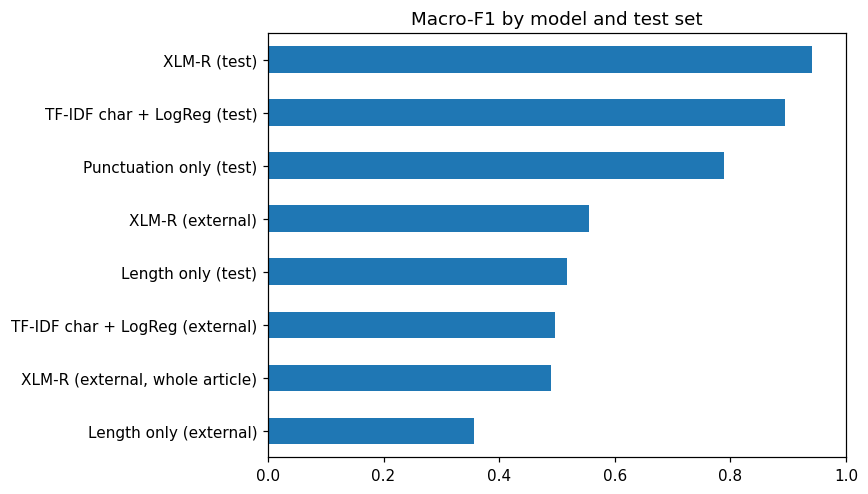

In [29]:
res = pd.DataFrame(results).T
res.to_csv(OUTPUT_DIR / "results.csv")
display(res)

plot_df = res["f1_macro"].sort_values()
plot_df.plot.barh(figsize=(8, 0.45 * len(plot_df) + 1), xlim=(0, 1), title="Macro-F1 by model and test set")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "results.png"); plt.show()

## 23. What to write in the FYP-2 report
- **Data:** sizes before/after de-duplication (steps 8–9) and the number of verdict-word rows removed (step 10). These are concrete contributions most papers on these datasets skip.
- **Baselines vs transformer:** the results table. Mention what the length-only baseline scored.
- **Generalisation:** in-domain vs Bend the Truth external score, both the first-tokens and the whole-article version
  (step 17b). Explain the gap: different length, style, writers and topics.
- **Limitations:**
  - translated fakes and topic bias in Hook and Bait;
  - each Hook and Bait file is one class from different outlets, so the model can partly learn outlet style;
  - de-duplication only removes exact copies, so reworded versions of the same story can sit in both train and test;
  - the verdict-word filter is a keyword list: check step 13's "towards FAKE" features for giveaways it missed;
  - headline-only training data versus full articles in the app;
  - no Roman Urdu yet (next step: transliterate `work/khabarnazar_urdu_merged.csv`).

---
# Part F (optional) — Explanations for the app
## 24. SHAP word importance
SHAP gives per-word scores like the app's highlights, with a more careful method than the backend's quick
word-removal check. It is for figures in the report; it takes seconds per text, so the backend does not use it.
Needs `pip install shap`; if it isn't installed this cell just prints a message.

In [30]:
try:
    import shap
except ImportError:
    shap = None
    print("shap is not installed: run  pip install shap  in the terminal, restart the kernel, then run this cell.")

if shap is not None:
    from transformers import pipeline

    pipe = pipeline("text-classification", model=str(MODEL_DIR), tokenizer=str(MODEL_DIR), top_k=None,
                    truncation=True, max_length=MAX_LEN, device=0 if torch.cuda.is_available() else -1)
    explainer = shap.Explainer(pipe)

    example = test_df[test_df.label == 1].text_clean.iloc[0]
    sv = explainer([example])
    shap.plots.text(sv[0, :, "FAKE"])

    def shap_to_json(sv_row, label="FAKE", top_n=10):
        pairs = [(t.strip(), float(v)) for t, v in zip(sv_row.data, sv_row[:, label].values) if t.strip()]
        pairs.sort(key=lambda x: abs(x[1]), reverse=True)
        return json.dumps([{"word": w, "score": round(s, 4)} for w, s in pairs[:top_n]], ensure_ascii=False)

    print(shap_to_json(sv[0]))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


[{"word": "نہیں", "score": 0.0029}, {"word": "کہ", "score": -0.0019}, {"word": "امریکی", "score": 0.0013}, {"word": "یس", "score": 0.001}, {"word": "ع", "score": -0.0007}, {"word": "ہونا", "score": -0.0005}, {"word": "یہ", "score": -0.0004}, {"word": "تا", "score": -0.0004}, {"word": "آئین", "score": -0.0004}, {"word": "ائی", "score": 0.0004}]


---
## 25. Google Colab only: save the model to Drive and push to GitHub
Skip this on your own computer (there you push from VS Code). In Colab it:
1. copies the trained model (about 1 GB) to **My Drive → KhabarNazar_models → xlmr**. GitHub can't hold it;
   later you copy this folder into `models/text/xlmr/` on any computer that runs the backend;
2. asks for your name, GitHub email and a GitHub token (typed hidden, never saved in the notebook);
3. checks that no big file is about to be uploaded, then commits the code and the results in `text_module/outputs/`
   and pushes them to the `text-model` branch.

In [ ]:
if IN_COLAB:
    import shutil, getpass
    drive_copy = Path("/content/drive/MyDrive/KhabarNazar_models/xlmr")
    if not Path("/content/drive/MyDrive").is_dir():
        try:
            drive.mount("/content/drive")
        except Exception as e:
            raise RuntimeError("Google Drive is not connected, so the model can't be saved. Click the folder icon "
                               "on the left -> 'Mount Drive', then run this cell again.") from e
    if (MODEL_DIR / "model.safetensors").exists():
        shutil.copytree(MODEL_DIR, drive_copy, dirs_exist_ok=True)
        print("model copied to Google Drive:", drive_copy)
    else:
        print("No trained model found in", MODEL_DIR, "- pushing code and results only")

    repo = str(COLAB_REPO)
    name  = input("Your name (for the commit): ").strip()
    email = input("Your GitHub email: ").strip()
    token = getpass.getpass("GitHub token (hidden): ").strip()
    sh("git", "-C", repo, "config", "user.name", name)
    sh("git", "-C", repo, "config", "user.email", email)
    sh("git", "-C", repo, "add", "-A")

    staged = sh("git", "-C", repo, "diff", "--cached", "--name-only").stdout.split("\n")
    big = [f for f in staged if f and (COLAB_REPO / f).is_file() and (COLAB_REPO / f).stat().st_size > 50_000_000]
    if big:
        sh("git", "-C", repo, "reset", "-q")
        raise RuntimeError(f"Stopped: these files are too big for GitHub: {big}. Nothing was pushed.")
    print("files to upload:")
    sh("git", "-C", repo, "status", "--short")

    if sh("git", "-C", repo, "diff", "--cached", "--quiet", check=False).returncode != 0:
        sh("git", "-C", repo, "commit", "-m", "Add Urdu XLM-RoBERTa text model and connect it to the backend")
    push = subprocess.run(["git", "-C", repo, "push", f"https://{token}@github.com/azmkh/KhabarNazar.git",
                           "text-model"], capture_output=True, text=True)
    output = (push.stdout + push.stderr).replace(token, "***")
    print(output.strip())
    print("PUSHED to the text-model branch" if push.returncode == 0 else "Push FAILED - see the message above")
    del token
else:
    print("Not in Colab: push from VS Code instead (see text_module/README.md).")